In [ ]:
import string 
import os
import Pathlib



import pandas

In [ ]:
df = pd.read_csv('/content/Egypt House Prices.csv')

In [ ]:
df.sample(10)

,HouseID,City,PropertyType,Area,NumRooms,Floor,BuildingAge,View,HasElevator,Price
3473,3474,Alexandria,Apartment,112.0,5.0,7,16.0,Street,Yes,558844.0
1671,1672,Giza,Villa,103.0,3.0,8,3.0,Street,Yes,357210.0
618,619,Giza,Apartment,101.0,3.0,1,27.0,Street,No,264572.0
2499,2500,Alexandria,Apartment,64.0,4.0,1,24.0,Street,No,292805.0
3652,3653,Giza,Apartment,155.0,5.0,10,29.0,Street,No,417995.0
1417,1418,Cairo,Villa,90.0,5.0,4,34.0,Garden,No,523856.0
802,803,Alexandria,Apartment,77.0,1.0,0,20.0,Street,No,164868.0
293,294,Cairo,Apartment,123.0,2.0,5,18.0,Garden,Yes,377855.0
2625,2626,Mansoura,Apartment,117.0,4.0,1,30.0,Garden,No,343571.0
4710,4711,Alexandria,Apartment,127.0,1.0,0,40.0,Street,Yes,212533.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   HouseID       5025 non-null   int64  
 1   City          5025 non-null   object 
 2   PropertyType  5025 non-null   object 
 3   Area          4950 non-null   float64
 4   NumRooms      4950 non-null   float64
 5   Floor         5025 non-null   int64  
 6   BuildingAge   4950 non-null   float64
 7   View          5025 non-null   object 
 8   HasElevator   5025 non-null   object 
 9   Price         5025 non-null   float64
dtypes: float64(4), int64(2), object(4)
memory usage: 392.7+ KB


In [ ]:
df.isnull().sum()

,0
HouseID,0
City,0
PropertyType,0
Area,75
NumRooms,75
Floor,0
BuildingAge,75
View,0
HasElevator,0
Price,0


In [ ]:
df = df.dropna()

In [ ]:
df = df.drop(columns = 'HouseID')

In [ ]:
df['City'].value_counts()

,count
City,
Cairo,2010
Alexandria,1482
Giza,984
Mansoura,474


In [ ]:
# cardinality

In [ ]:
df['PropertyType'].value_counts()

,count
PropertyType,
Apartment,3994
Villa,956


In [ ]:
df['View'].value_counts()

,count
View,
Street,3483
Garden,1467


In [ ]:
df['HasElevator'].value_counts()

,count
HasElevator,
Yes,2985
No,1965


In [ ]:
df.groupby('PropertyType')['Price'].mean()

,Price
PropertyType,
Apartment,389077.384827
Villa,396978.844142


In [ ]:
df['HasElevator'] = df['HasElevator'].replace({'Yes': 1, 'No': 0})
df['PropertyType'] = df['PropertyType'].replace({'Villa': 1, 'Apartment': 0})
df['View'] = df['View'].replace({'Garden': 1, 'Street': 0})

/tmp/ipykernel_457/3571971454.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['HasElevator'] = df['HasElevator'].replace({'Yes': 1, 'No': 0})
/tmp/ipykernel_457/3571971454.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['PropertyType'] = df['PropertyType'].replace({'Villa': 1, 'Apartment': 0})
/tmp/ipykernel_457/3571971454.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-

In [ ]:
df

,City,PropertyType,Area,NumRooms,Floor,BuildingAge,View,HasElevator,Price
0,Cairo,0,75.0,3.0,10,25.0,0,1,451622.0
1,Mansoura,0,86.0,4.0,3,20.0,0,1,319612.0
2,Giza,1,132.0,1.0,3,20.0,1,1,243657.0
3,Alexandria,0,85.0,5.0,9,11.0,1,1,553189.0
4,Cairo,1,153.0,4.0,8,22.0,1,1,638983.0
...,...,...,...,...,...,...,...,...,...
4995,Giza,1,150.0,1.0,5,6.0,0,1,256993.0
4996,Cairo,1,119.0,2.0,10,16.0,0,1,381430.0
4997,Cairo,1,114.0,2.0,3,21.0,1,1,440343.0
4998,Giza,0,83.0,4.0,0,3.0,0,1,373376.0


In [ ]:
ohe = OneHotEncoder( sparse_output = False)
city_encoded = ohe.fit_transform(df[['City']])
city_cols = ohe.get_feature_names_out(['City'])


In [ ]:
city_df = pd.DataFrame(city_encoded, columns=city_cols,index = df.index)

In [ ]:
city_df

,City_Alexandria,City_Cairo,City_Giza,City_Mansoura
0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,1.0
2,0.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0
4,0.0,1.0,0.0,0.0
...,...,...,...,...
4995,0.0,0.0,1.0,0.0
4996,0.0,1.0,0.0,0.0
4997,0.0,1.0,0.0,0.0
4998,0.0,0.0,1.0,0.0


In [ ]:
df = pd.concat([df.drop(columns = ['City']),city_df],axis = 1)
df

,PropertyType,Area,NumRooms,Floor,BuildingAge,View,HasElevator,Price,City_Alexandria,City_Cairo,City_Giza,City_Mansoura
0,0,75.0,3.0,10,25.0,0,1,451622.0,0.0,1.0,0.0,0.0
1,0,86.0,4.0,3,20.0,0,1,319612.0,0.0,0.0,0.0,1.0
2,1,132.0,1.0,3,20.0,1,1,243657.0,0.0,0.0,1.0,0.0
3,0,85.0,5.0,9,11.0,1,1,553189.0,1.0,0.0,0.0,0.0
4,1,153.0,4.0,8,22.0,1,1,638983.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,1,150.0,1.0,5,6.0,0,1,256993.0,0.0,0.0,1.0,0.0
4996,1,119.0,2.0,10,16.0,0,1,381430.0,0.0,1.0,0.0,0.0
4997,1,114.0,2.0,3,21.0,1,1,440343.0,0.0,1.0,0.0,0.0
4998,0,83.0,4.0,0,3.0,0,1,373376.0,0.0,0.0,1.0,0.0


In [ ]:
city_cols

array(['City_Alexandria', 'City_Cairo', 'City_Giza', 'City_Mansoura'],
      dtype=object)

In [ ]:
X = df.drop(columns = 'Price')
y = df['Price']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
mse = mean_squared_error(y_test, y_pred)
mse

2464331961.6155095

In [ ]:
mae = mean_absolute_error(y_test, y_pred)  
mae

39571.99276491862

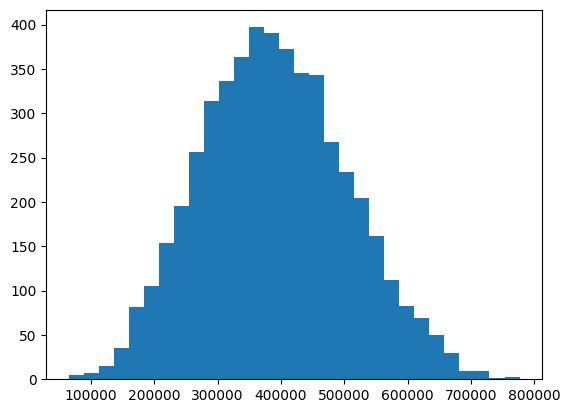

In [ ]:
plt.hist(df['Price'], bins = 30)
plt.show()

In [ ]:
# save_model
joblib.dump(model, 'model.pkl') 

['model.pkl']

In [ ]:
joblib.dump(ohe, 'ohe.pkl')

['ohe.pkl']

In [ ]:
# api

In [ ]:
# project
     # pkl files
          #  ML models < model.pkl
          #  preprcoesing.pkl < ohe.pkl < standard scaler

     # app.py
     # utlis / helper function
     # requirements.txt

In [ ]:
from flask import Flask, request, jsonify
import joblib
import pandas as pd

app = Flask(__name__)

# Load the trained model and preprocessing objects
model = joblib.load('model.pkl')
ohe = joblib.load('ohe.pkl')

# Get the feature names from the OHE object directly after loading
# This ensures that the feature names match what the OHE was fitted with
ohe_city_feature_names_trained = ohe.get_feature_names_out(['City'])

# Define the full list of expected columns in the exact order the model was trained
# This needs to be consistent with the X dataframe used for model.fit()
expected_columns_order_trained = [
    'PropertyType', 'Area', 'NumRooms', 'Floor', 'BuildingAge', 'View', 'HasElevator'
] + list(ohe_city_feature_names_trained)

def preprocess_input(df_input):
    df_processed = df_input.copy()

    # Map binary categorical features
    df_processed['HasElevator'] = df_processed['HasElevator'].map({'Yes': 1, 'No': 0})
    df_processed['View'] = df_processed['View'].map({'Street': 0, 'Garden': 1})
    df_processed['PropertyType'] = df_processed['PropertyType'].map({'Apartment': 0, 'Villa': 1})

    # One-hot encode 'City'
    cat_col = 'City'
    city_encoded = ohe.transform(df_processed[[cat_col]])

    # Create DataFrame for one-hot encoded city features
    # Use the feature names derived from the *trained* ohe object
    city_df = pd.DataFrame(city_encoded, columns=ohe_city_feature_names_trained, index=df_processed.index)

    # Combine numerical and one-hot encoded features, dropping the original 'City' column
    df_processed = pd.concat([df_processed.drop(columns=[cat_col]), city_df], axis=1)

    # Reorder columns to match the training data's exact order
    df_processed = df_processed[expected_columns_order_trained]

    return df_processed

@app.route('/predict', methods=['POST'])
def predict():
    data = request.get_json()
    df = pd.DataFrame([data])
    df_processed = preprocess_input(df)
    prediction = model.predict(df_processed)

    return jsonify({'prediction': prediction[0]})



if __name__ == '__main__':
    app.run(debug=True)

 * Serving Flask app '__main__'
 * Debug mode: on


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit
INFO:werkzeug: * Restarting with watchdog (inotify)
ERROR:root:Unexpected exception finding object shape
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/google/colab/_debugpy_repr.py", line 54, in get_shape
    shape = getattr(obj, 'shape', None)
            ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/werkzeug/local.py", line 318, in __get__
    obj = instance._get_current_object()
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/werkzeug/local.py", line 519, in _get_current_object
    raise RuntimeError(unbound_message) from None
RuntimeError: Working outside of request context.

This typically means that you attempted to use functionality that needed
an active HTTP request. Cons

In [ ]:
import requests

In [ ]:
import requests
import json

url = "https://b9f7ebac97ca.ngrok-free.app/predict"

data = {
    "PropertyType": "Apartment",

"City": "Cairo",
"Area": 120,
"NumRooms": 3,
"Floor": 5,
"BuildingAge": 10,
"View": "Garden",
"HasElevator": "Yes"
}


response = requests.post(url, json=data)
print(response.json())

{'predicted_price': 512108.95666363975}
